In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

monthly_crime = pd.read_csv(
    "../data/processed/monthly_neighbourhood_crime.csv",
    parse_dates=["OCC_DATE"]
)

print("Dataset shape:", monthly_crime.shape)
monthly_crime.head()

Dataset shape: (23700, 3)


,OCC_DATE,NEIGHBOURHOOD_158,crime_count
0,2014-01-01,Agincourt North (129),16
1,2014-01-01,Agincourt South-Malvern West (128),31
2,2014-01-01,Alderwood (20),7
3,2014-01-01,Annex (95),35
4,2014-01-01,Avondale (153),4


In [2]:
monthly_total = (
    monthly_crime
    .groupby("OCC_DATE")["crime_count"]
    .sum()
)

print("Number of months:", len(monthly_total))
print("\nFirst 5 months:")
print(monthly_total.head())

print("\nLast 5 months:")
print(monthly_total.tail())

Number of months: 150

First 5 months:
OCC_DATE
2014-01-01    2240
2014-02-01    1975
2014-03-01    2185
2014-04-01    2239
2014-05-01    2530
Name: crime_count, dtype: int64

Last 5 months:
OCC_DATE
2026-02-01    2659
2026-03-01    3090
2026-04-01    2961
2026-05-01    3147
2026-06-01    3016
Name: crime_count, dtype: int64


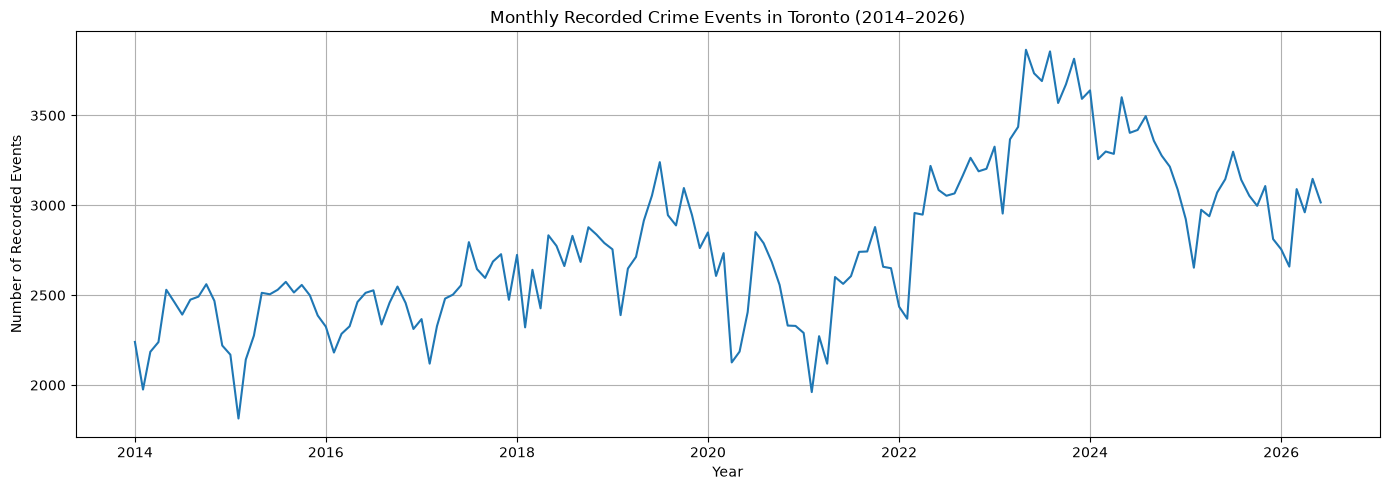

In [3]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_total.index,
    monthly_total.values
)

plt.title("Monthly Recorded Crime Events in Toronto (2014–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Recorded Events")

plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
monthly_total_complete = monthly_total[
    monthly_total.index.year < 2026
]

seasonal_pattern = (
    monthly_total_complete
    .groupby(monthly_total_complete.index.month)
    .mean()
)

seasonal_pattern.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(seasonal_pattern.round(0))

Jan    2670.0
Feb    2383.0
Mar    2653.0
Apr    2610.0
May    2858.0
Jun    2850.0
Jul    2922.0
Aug    2908.0
Sep    2851.0
Oct    2914.0
Nov    2854.0
Dec    2718.0
Name: crime_count, dtype: float64


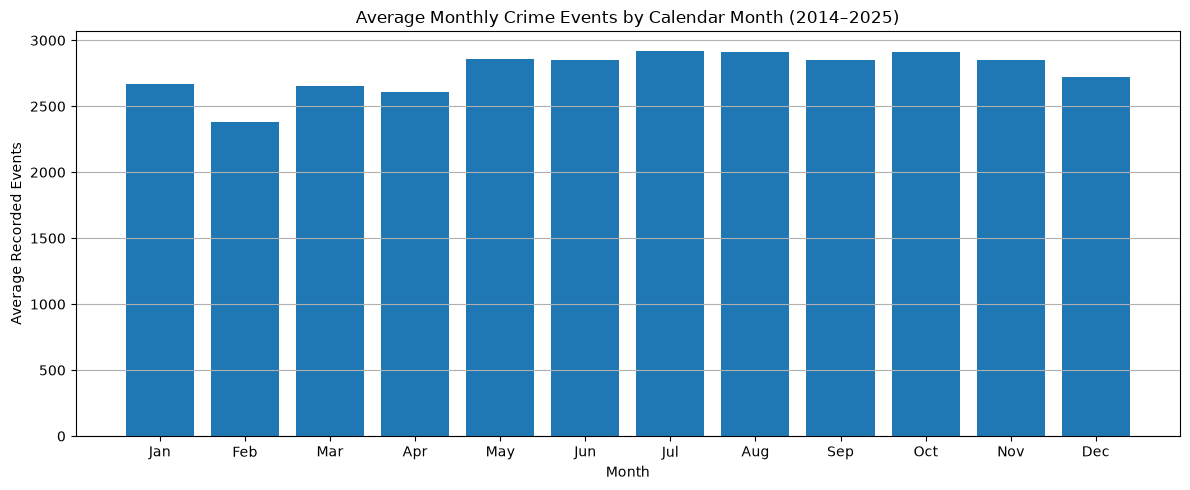

In [5]:
plt.figure(figsize=(12, 5))

plt.bar(seasonal_pattern.index, seasonal_pattern.values)

plt.title("Average Monthly Crime Events by Calendar Month (2014–2025)")
plt.xlabel("Month")
plt.ylabel("Average Recorded Events")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [6]:
highest_month = seasonal_pattern.idxmax()
lowest_month = seasonal_pattern.idxmin()

seasonal_range = (
    seasonal_pattern.max() - seasonal_pattern.min()
)

seasonal_percentage = (
    seasonal_range / seasonal_pattern.mean()
) * 100

print("Highest month:", highest_month,
      round(seasonal_pattern.max()))

print("Lowest month:", lowest_month,
      round(seasonal_pattern.min()))

print("Difference:", round(seasonal_range))

print("Seasonal range as % of average:",
      round(seasonal_percentage, 2), "%")

Highest month: Jul 2922
Lowest month: Feb 2383
Difference: 539
Seasonal range as % of average: 19.47 %


In [7]:
yearly_total = (
    monthly_total_complete
    .groupby(monthly_total_complete.index.year)
    .sum()
)

print("Annual recorded crime events:")
print(yearly_total)

Annual recorded crime events:
OCC_DATE
2014    28238
2015    28480
2016    28733
2017    30278
2018    32402
2019    34351
2020    30450
2021    30083
2022    35953
2023    42878
2024    40338
2025    36115
Name: crime_count, dtype: int64


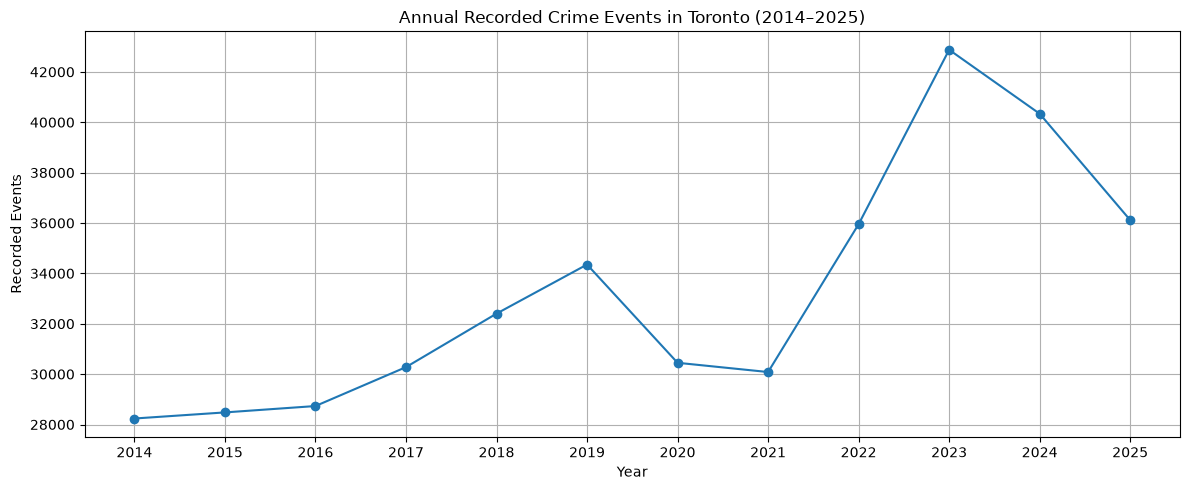

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_total.index,
    yearly_total.values,
    marker="o"
)

plt.title("Annual Recorded Crime Events in Toronto (2014–2025)")
plt.xlabel("Year")
plt.ylabel("Recorded Events")
plt.xticks(yearly_total.index)
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
yearly_change = yearly_total.pct_change() * 100

yearly_summary = pd.DataFrame({
    "total_crimes": yearly_total,
    "year_over_year_change_%": yearly_change
})

print(yearly_summary.round(2))

          total_crimes  year_over_year_change_%
OCC_DATE                                       
2014             28238                      NaN
2015             28480                     0.86
2016             28733                     0.89
2017             30278                     5.38
2018             32402                     7.01
2019             34351                     6.02
2020             30450                   -11.36
2021             30083                    -1.21
2022             35953                    19.51
2023             42878                    19.26
2024             40338                    -5.92
2025             36115                   -10.47


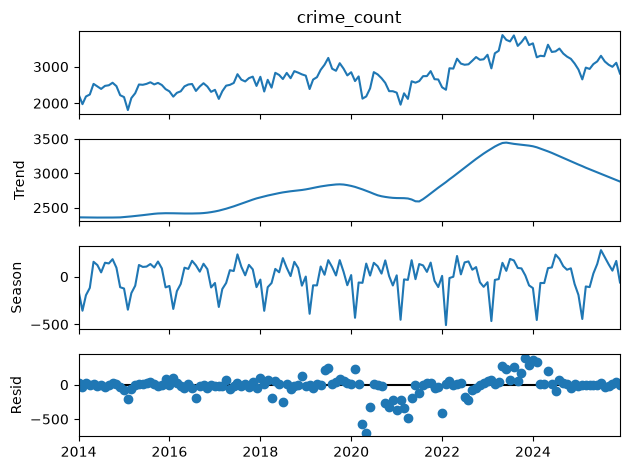

In [10]:
from statsmodels.tsa.seasonal import STL

stl_model = STL(
    monthly_total_complete,
    period=12,
    robust=True
)

stl_result = stl_model.fit()

stl_result.plot()
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

residual_variance = np.var(stl_result.resid)

trend_strength = max(
    0,
    1 - residual_variance /
    np.var(stl_result.trend + stl_result.resid)
)

seasonal_strength = max(
    0,
    1 - residual_variance /
    np.var(stl_result.seasonal + stl_result.resid)
)

print("Trend strength:", round(trend_strength, 3))
print("Seasonal strength:", round(seasonal_strength, 3))

Trend strength: 0.867
Seasonal strength: 0.501


In [12]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(monthly_total_complete)

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

ADF statistic: -2.4183
p-value: 0.1366
Critical values:
1%: -3.4821
5%: -2.8842
10%: -2.5789


/var/folders/64/7_9hsj_d5cq68j70r1zxf7ym0000gn/T/ipykernel_56686/1326511697.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(monthly_total_complete)


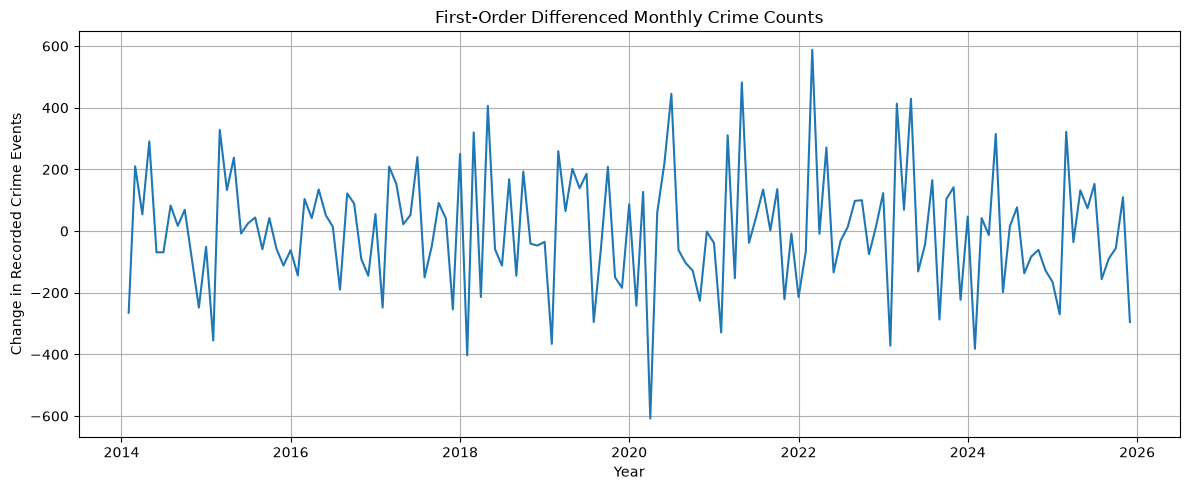

ADF statistic: -2.0443
p-value: 0.2675
5% critical value: -2.8842


/var/folders/64/7_9hsj_d5cq68j70r1zxf7ym0000gn/T/ipykernel_56686/2071543519.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(crime_diff)


In [13]:
# First-order differencing
crime_diff = monthly_total_complete.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(12, 5))

plt.plot(crime_diff)

plt.title("First-Order Differenced Monthly Crime Counts")
plt.xlabel("Year")
plt.ylabel("Change in Recorded Crime Events")
plt.grid(True)
plt.tight_layout()
plt.show()

# Run ADF test again
adf_diff = adfuller(crime_diff)

print("ADF statistic:", round(adf_diff[0], 4))
print("p-value:", round(adf_diff[1], 4))
print("5% critical value:", round(adf_diff[4]["5%"], 4))

In [14]:
seasonal_diff = crime_diff.diff(12).dropna()

adf_result = adfuller(seasonal_diff)

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("5% critical value:", round(adf_result[4]["5%"], 4))

ADF statistic: -3.3179
p-value: 0.0141
5% critical value: -2.8862


/var/folders/64/7_9hsj_d5cq68j70r1zxf7ym0000gn/T/ipykernel_56686/2436839253.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(seasonal_diff)


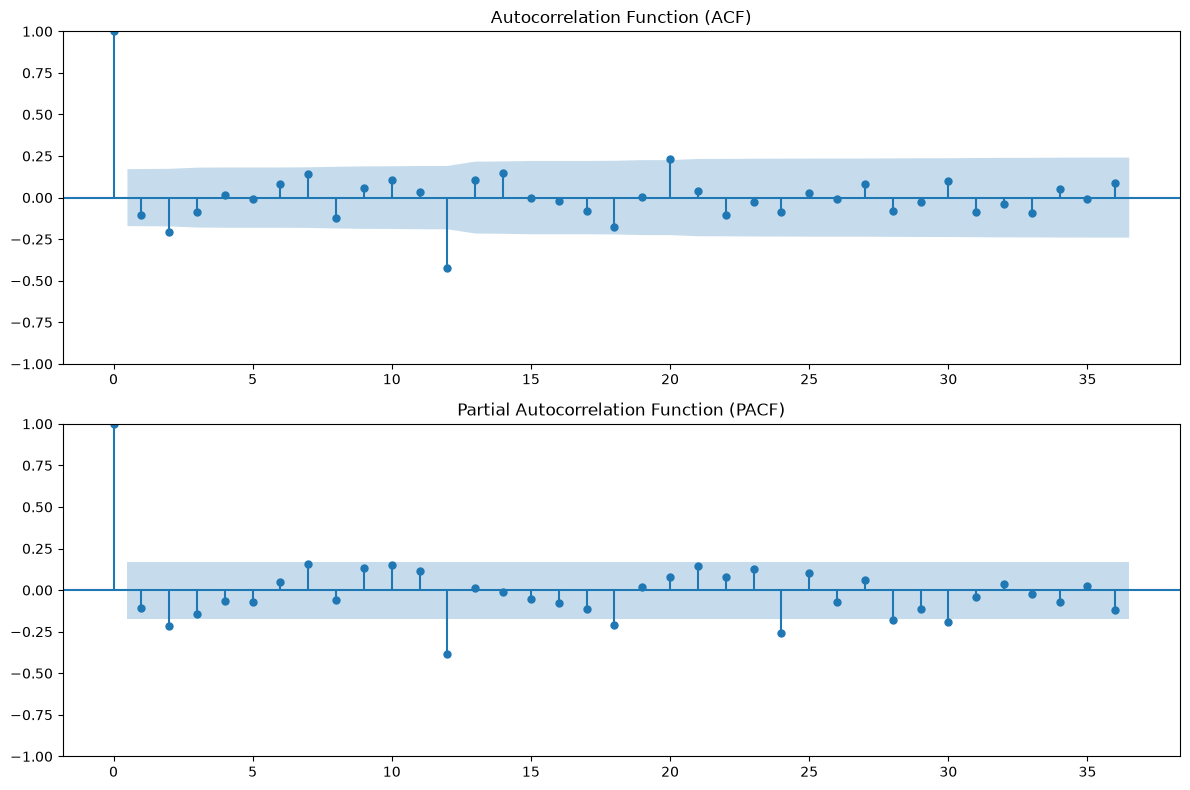

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(seasonal_diff, lags=36, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(seasonal_diff, lags=36, ax=axes[1], method="ywm")
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()